# Phase 1 — Environment & Data Setup
## Dataset Verification + Mask Coverage

Reference: `Phase-1_Implementation.md`, `Phase-1_Updated.md`

This notebook covers the **Data Setup** section only:
- Dataset verification (image count, metadata count, corrupted files, missing/extra)
- Segmentation mask coverage per class

**Revision note (v2):** the mask source was corrected after the original ISIC 2018
Challenge Task 1 ground-truth masks were found to have **0% overlap** with HAM10000
(confirmed programmatically across all 3,694 masks — different, non-overlapping
`image_id` range, ~ISIC_0000031–0023449 vs. HAM10000's ~ISIC_0024306–0034320).
HAM10000's own documentation confirms it pairs with ISIC 2018 **Task 3**
(classification), not Task 1 (segmentation) — the two are unrelated image pools
that happen to share a challenge year.

The correct mask source is `HAM10000_segmentations_lesion_tschandl.zip`
(Harvard Dataverse), curated specifically for HAM10000 by Tschandl's team —
verified below at **10,015 / 10,015** overlap, i.e. full coverage.

In [1]:
import os
from pathlib import Path
import pandas as pd
from PIL import Image
from collections import defaultdict

# ── Config — adjust paths if your folder names differ ──────────────────────
PROJECT_ROOT = Path(r"T:/Thesis - Development")
DATASET_ROOT = PROJECT_ROOT / "Resources" / "Dataset"

HAM_ROOT = DATASET_ROOT / "HAM10000"
HAM_IMAGES_DIR = HAM_ROOT / "images"
HAM_METADATA_PATH = HAM_ROOT / "HAM10000_metadata.tab"

# Corrected mask source (see revision note above).
# ISIC2018_Masks/ is kept on disk for provenance but is NOT used —
# it does not correspond to HAM10000.
MASKS_ROOT = DATASET_ROOT / "HAM10000_Tschandl_Segmentations"

EXPECTED_IMAGE_COUNT = 10015
EXPECTED_METADATA_ROWS = 10015

print(f"HAM10000 images dir : {HAM_IMAGES_DIR}")
print(f"HAM10000 metadata   : {HAM_METADATA_PATH}")
print(f"Mask source (Tschandl): {MASKS_ROOT}")

HAM10000 images dir : T:\Thesis - Development\Resources\Dataset\HAM10000\images
HAM10000 metadata   : T:\Thesis - Development\Resources\Dataset\HAM10000\HAM10000_metadata.tab
Mask source (Tschandl): T:\Thesis - Development\Resources\Dataset\HAM10000_Tschandl_Segmentations


---
## 1. Dataset Verification

Checks, run as a set (nothing stops early):
1. Image count matches 10,015
2. Metadata row count matches 10,015
3. No corrupted image files (`PIL.Image.verify()`)
4. No missing images (in metadata, not on disk)
5. No extra images (on disk, not in metadata)

In [2]:
failures = []
warnings = []

# --- Locate all image files recursively (handles flat or nested extraction) ---
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png"}
image_paths = [p for p in HAM_IMAGES_DIR.rglob("*") if p.suffix.lower() in VALID_EXTENSIONS]
image_id_to_path = {p.stem: p for p in image_paths}

found_image_count = len(image_paths)
print(f"Found {found_image_count} image files under {HAM_IMAGES_DIR}")

if found_image_count != EXPECTED_IMAGE_COUNT:
    failures.append(
        f"Image count mismatch: found {found_image_count}, expected {EXPECTED_IMAGE_COUNT}"
    )

# --- Duplicate-stem check (two zips extracting into overlapping names) ---
if len(image_id_to_path) != found_image_count:
    dupe_count = found_image_count - len(image_id_to_path)
    failures.append(
        f"{dupe_count} duplicate image_id(s) found across image files — "
        f"check for overlapping extraction from part_1/part_2 zips"
    )

Found 10015 image files under T:\Thesis - Development\Resources\Dataset\HAM10000\images


In [3]:
# --- Load metadata ---
metadata_df = pd.read_csv(HAM_METADATA_PATH, sep="\t")

print(f"Metadata columns: {list(metadata_df.columns)}")
print(f"Metadata rows: {len(metadata_df)}")

if len(metadata_df) != EXPECTED_METADATA_ROWS:
    failures.append(
        f"Metadata row count mismatch: found {len(metadata_df)}, expected {EXPECTED_METADATA_ROWS}"
    )

if "image_id" not in metadata_df.columns:
    failures.append("metadata is missing an 'image_id' column — cannot cross-reference")
if "dx" not in metadata_df.columns:
    failures.append("metadata is missing a 'dx' column — needed for per-class mask coverage later")
if "lesion_id" not in metadata_df.columns:
    warnings.append("metadata is missing a 'lesion_id' column — needed for Phase 1 splitting step")

Metadata columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']
Metadata rows: 10015


In [4]:
# --- Missing / extra cross-check ---
metadata_ids = set(metadata_df["image_id"]) if "image_id" in metadata_df.columns else set()
disk_ids = set(image_id_to_path.keys())

missing_from_disk = metadata_ids - disk_ids   # in metadata, no image file
extra_on_disk = disk_ids - metadata_ids       # image file, not in metadata

if missing_from_disk:
    failures.append(f"{len(missing_from_disk)} image_id(s) in metadata have no corresponding image file")
if extra_on_disk:
    failures.append(f"{len(extra_on_disk)} image file(s) on disk have no corresponding metadata row")

print(f"Missing from disk: {len(missing_from_disk)}")
print(f"Extra on disk:     {len(extra_on_disk)}")

Missing from disk: 0
Extra on disk:     0


In [5]:
# --- Corrupted-file check ---
corrupted = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as e:
        corrupted.append((path.name, str(e)))

if corrupted:
    failures.append(f"{len(corrupted)} corrupted image file(s) found")

print(f"Corrupted files: {len(corrupted)}")
if corrupted:
    for name, err in corrupted[:20]:
        print(f"  {name}: {err}")
    if len(corrupted) > 20:
        print(f"  ... and {len(corrupted) - 20} more")

Corrupted files: 0


In [6]:
# --- Report: fail loudly as a set ---
print("=" * 60)
if warnings:
    print(f"WARNINGS ({len(warnings)}):")
    for w in warnings:
        print(f"  - {w}")
    print()

if failures:
    print(f"FAILED — {len(failures)} check(s) did not pass:")
    for f in failures:
        print(f"  - {f}")
    raise AssertionError(f"Dataset verification failed: {len(failures)} check(s) did not pass. See above.")
else:
    print("ALL CHECKS PASSED")
    print(f"  Images verified   : {found_image_count}")
    print(f"  Metadata rows     : {len(metadata_df)}")
    print(f"  Corrupted files   : 0")
    print(f"  Missing / extra   : 0 / 0")

ALL CHECKS PASSED
  Images verified   : 10015
  Metadata rows     : 10015
  Corrupted files   : 0
  Missing / extra   : 0 / 0


---
## 2. Segmentation Mask Coverage — Per Class

**Source:** `HAM10000_segmentations_lesion_tschandl.zip` (Harvard Dataverse) —
curated specifically for HAM10000, not the ISIC 2018 Challenge Task 1 masks
(see revision note at the top of this notebook for why the latter was rejected).

Filenames follow the pattern `ISIC_XXXXXXX_segmentation.png`, matching HAM10000's
`image_id` directly. The extracted zip also contains a `__MACOSX` folder (macOS
metadata junk) and `._`-prefixed AppleDouble files — both are filtered out below,
they are not real mask data.

In [7]:
# --- Locate all mask files, filtering macOS junk ---
mask_paths = [
    p for p in MASKS_ROOT.rglob("*")
    if p.suffix.lower() == ".png"
    and "__MACOSX" not in p.parts
    and not p.name.startswith("._")
]

print(f"Found {len(mask_paths)} mask files under {MASKS_ROOT}")
print("Sample filenames:", [p.name for p in mask_paths[:5]])

# Mask filenames look like: ISIC_0024306_segmentation.png -> extract ISIC_0024306
def mask_path_to_image_id(path: Path) -> str:
    stem = path.stem  # e.g. ISIC_0024306_segmentation
    return stem.replace("_segmentation", "")

mask_image_ids = {mask_path_to_image_id(p) for p in mask_paths}
print(f"Unique image_ids with a mask: {len(mask_image_ids)}")

overall_overlap = metadata_ids & mask_image_ids
print(f"Overlap with HAM10000: {len(overall_overlap)} / {len(metadata_ids)}")

if len(overall_overlap) != len(metadata_ids):
    warnings.append(
        f"Mask coverage is not complete: {len(overall_overlap)}/{len(metadata_ids)} "
        f"HAM10000 images have a matching mask"
    )

Found 10015 mask files under T:\Thesis - Development\Resources\Dataset\HAM10000_Tschandl_Segmentations
Sample filenames: ['ISIC_0024306_segmentation.png', 'ISIC_0024307_segmentation.png', 'ISIC_0024308_segmentation.png', 'ISIC_0024309_segmentation.png', 'ISIC_0024310_segmentation.png']
Unique image_ids with a mask: 10015
Overlap with HAM10000: 10015 / 10015


In [8]:
# --- Per-class coverage ---
coverage_rows = []

for dx_class, group in metadata_df.groupby("dx"):
    class_image_ids = set(group["image_id"])
    class_total = len(class_image_ids)
    class_with_mask = len(class_image_ids & mask_image_ids)
    coverage_pct = 100 * class_with_mask / class_total if class_total else 0.0
    coverage_rows.append({
        "class": dx_class,
        "total_images": class_total,
        "images_with_mask": class_with_mask,
        "coverage_pct": round(coverage_pct, 1),
    })

coverage_df = pd.DataFrame(coverage_rows).sort_values("total_images", ascending=False).reset_index(drop=True)

# Overall row
overall_total = len(metadata_ids)
overall_with_mask = len(overall_overlap)
overall_pct = round(100 * overall_with_mask / overall_total, 1) if overall_total else 0.0

print(coverage_df.to_string(index=False))
print("-" * 50)
print(f"{'OVERALL':<10} total={overall_total:<6} with_mask={overall_with_mask:<6} coverage={overall_pct}%")

class  total_images  images_with_mask  coverage_pct
   nv          6705              6705         100.0
  mel          1113              1113         100.0
  bkl          1099              1099         100.0
  bcc           514               514         100.0
akiec           327               327         100.0
 vasc           142               142         100.0
   df           115               115         100.0
--------------------------------------------------
OVERALL    total=10015  with_mask=10015  coverage=100.0%


In [9]:
# --- Save coverage table + mask source provenance to Artifacts ---
ARTIFACTS_DIR = PROJECT_ROOT / "Resources" / "Artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

coverage_out_path = ARTIFACTS_DIR / "mask_coverage_per_class.csv"
coverage_df.to_csv(coverage_out_path, index=False)
print(f"Saved mask coverage table to: {coverage_out_path}")

provenance_note = (
    "Mask source: HAM10000_segmentations_lesion_tschandl.zip (Harvard Dataverse), "
    "NOT ISIC 2018 Challenge Task 1 ground truth.\n"
    "Reason: ISIC 2018 Task 1 masks were found to have 0% overlap with HAM10000 "
    "image_ids across all 3,694 masks (train+val+test) — confirmed programmatically. "
    "HAM10000's own Dataverse documentation confirms it pairs with ISIC 2018 Task 3 "
    "(classification) only, not Task 1 (segmentation).\n"
    f"Tschandl file overlap: {overall_with_mask}/{overall_total} ({overall_pct}%).\n"
    "Follow-up required: verify what mask source Javaid et al. (2025) and Gamage et al. "
    "(2024) actually used before citing 'same masks' comparability in Section 5.3/5.7."
)
provenance_path = ARTIFACTS_DIR / "mask_source_provenance_note.txt"
provenance_path.write_text(provenance_note)
print(f"Saved provenance note to: {provenance_path}")

Saved mask coverage table to: T:\Thesis - Development\Resources\Artifacts\mask_coverage_per_class.csv
Saved provenance note to: T:\Thesis - Development\Resources\Artifacts\mask_source_provenance_note.txt


---
## Exit Check — Data Setup

- [x] Image count verified against 10,015
- [x] Metadata row count verified against 10,015
- [x] Corrupted-file check run across all images
- [x] Missing / extra image_id cross-check run
- [x] Mask coverage recorded **per class**, not just an aggregate number
- [x] Coverage table saved to `Resources/Artifacts/` for reuse in Phase 4/5.5
- [x] Mask source corrected (ISIC 2018 Task 1 → Tschandl HAM10000 segmentations) and provenance documented

**Open item carried into the Phase 1 summary doc:** Section 5.3/5.7's claim that
the XAI masks are "the same masks used by Javaid and Gamage" is now unverified —
needs checking against their actual source papers before write-up.

Next: hair detection + removal, CLAHE, resize/crop pipeline.

HAIR DETECTION V3

In [21]:
import cv2
import numpy as np


def detect_hair_mask(
    image_bgr: np.ndarray,
    lesion_mask: np.ndarray = None,   # NEW: 255 = lesion, 0 = background skin. If given, lesion interior is fully excluded.
    blackhat_kernel_sizes: tuple = (9, 17),
    gaussian_blur_ksize: tuple = (3, 3),
    adaptive_block_size: int = 25,
    adaptive_C: int = -2,
    morph_kernel_size: int = 3,
    min_component_area: int = 15,
    max_extent_for_hair: float = 0.25,
    min_bbox_diagonal: int = 10,
) -> np.ndarray:
    """
    Detect hair artifacts in a dermoscopic image and return a binary mask
    (255 = hair, 0 = background/lesion), same H×W as input.

    v3 change: hair detection was found (via overlay diagnostic) to
    misidentify lesion pigment-network texture as hair — both produce
    thin, low-extent dark structures that look similar to the detector.
    Rather than trying to distinguish them (unreliable), the lesion
    interior is now fully excluded from detection using the ground-truth
    Tschandl segmentation mask. Trade-off, disclosed: hair strands that
    physically overlap the lesion will not be removed from the overlapping
    portion — a known limitation shared with established methods (e.g.
    DullRazor), preferred over any risk of corrupting lesion texture.

    Steps:
      1. Multi-scale BlackHat (small + large kernel), fused via pixel-wise max
      2. Gaussian blur to suppress speckle before thresholding
      3. Dual thresholding: adaptive Gaussian + global Otsu, OR-fused
      4. Morphological open then close
      5. NEW: zero out any response inside the lesion mask, BEFORE
         connected-component analysis (so a component straddling the
         boundary is truncated cleanly, not miscounted as one shape)
      6. Connected-component filtering by area and extent (fill ratio)
    """
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    # --- 1. Multi-scale BlackHat, fused via max ---
    blackhat_responses = []
    for k in blackhat_kernel_sizes:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
        blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
        blackhat_responses.append(blackhat)

    fused_blackhat = blackhat_responses[0]
    for response in blackhat_responses[1:]:
        fused_blackhat = np.maximum(fused_blackhat, response)

    # --- 2. Gaussian blur ---
    blurred = cv2.GaussianBlur(fused_blackhat, gaussian_blur_ksize, 0)

    # --- 3. Dual thresholding, OR-fused ---
    adaptive_thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
        adaptive_block_size, adaptive_C,
    )
    _, otsu_thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    fused_thresh = cv2.bitwise_or(adaptive_thresh, otsu_thresh)

    # --- 4. Morphological open then close ---
    morph_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (morph_kernel_size,) * 2)
    opened = cv2.morphologyEx(fused_thresh, cv2.MORPH_OPEN, morph_kernel)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, morph_kernel)

    # --- 5. Exclude lesion interior BEFORE connected-component analysis ---
    if lesion_mask is not None:
        if lesion_mask.shape != closed.shape:
            raise ValueError(
                f"lesion_mask shape {lesion_mask.shape} does not match image shape {closed.shape} — "
                f"resize/align them before calling detect_hair_mask"
            )
        closed = cv2.bitwise_and(closed, cv2.bitwise_not(lesion_mask))

    # --- 6. Connected-component filtering (extent-based) ---
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed, connectivity=8)

    final_mask = np.zeros_like(closed)

    for label_id in range(1, num_labels):
        area = stats[label_id, cv2.CC_STAT_AREA]
        width = stats[label_id, cv2.CC_STAT_WIDTH]
        height = stats[label_id, cv2.CC_STAT_HEIGHT]
        bbox_area = width * height
        bbox_diagonal = (width**2 + height**2) ** 0.5

        if area < min_component_area:
            continue
        if bbox_diagonal < min_bbox_diagonal:
            continue

        extent = area / bbox_area if bbox_area > 0 else 1.0
        if extent > max_extent_for_hair:
            continue

        final_mask[labels == label_id] = 255

    return final_mask

HAIR REMOVAL

In [22]:
import cv2
import numpy as np


def remove_hair(
    image_bgr: np.ndarray,
    hair_mask: np.ndarray,
    dilate_kernel_size: int = 3,
    dilate_iterations: int = 1,
    inpaint_radius: int = 3,
) -> np.ndarray:
    """
    Remove detected hair from an image via mask-guided inpainting (TELEA).

    Args:
        image_bgr: original BGR image, H×W×3
        hair_mask: binary mask from detect_hair_mask(), 255 = hair, same H×W
        dilate_kernel_size: mask is dilated slightly before inpainting so the
            fill covers hair edges/anti-aliasing, not just the hair core
        dilate_iterations: how many times to apply the dilation
        inpaint_radius: radius of the neighborhood used by TELEA for each
            inpainted pixel

    Returns:
        Hair-removed BGR image, same shape as input.
    """
    dilate_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (dilate_kernel_size, dilate_kernel_size)
    )
    dilated_mask = cv2.dilate(hair_mask, dilate_kernel, iterations=dilate_iterations)

    inpainted = cv2.inpaint(
        image_bgr,
        dilated_mask,
        inpaintRadius=inpaint_radius,
        flags=cv2.INPAINT_TELEA,
    )

    return inpainted

HAIR VALIDATION DRIVER

ISIC_0026130: hair pixels = 3.47%
ISIC_0024715: hair pixels = 3.06%
ISIC_0028812: hair pixels = 2.60%
ISIC_0028318: hair pixels = 4.62%
ISIC_0027963: hair pixels = 0.00%
ISIC_0026592: hair pixels = 0.00%
ISIC_0025985: hair pixels = 4.02%
ISIC_0033241: hair pixels = 12.78%


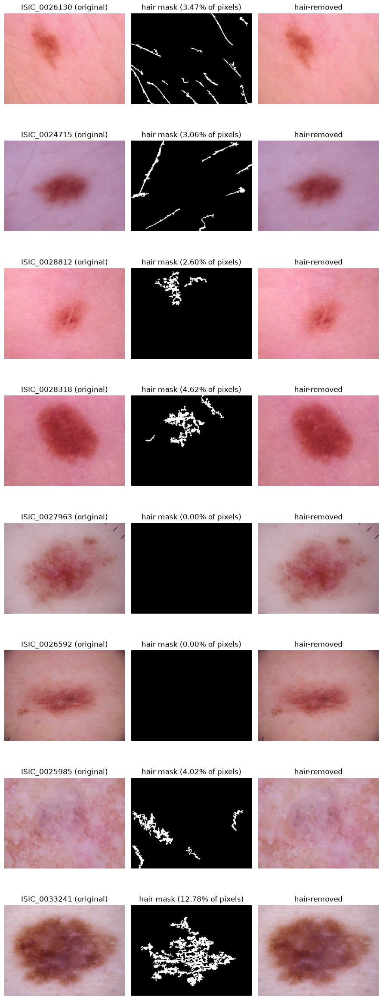


Validation masks saved to: T:\Thesis - Development\Resources\Artifacts\HairMasks_ValidationSample
Inspect the grid above — check that:
  1. Detected mask actually traces visible hair strands (not lesion border/noise)
  2. Hair-removed image shows hair gone with no visible inpainting artifacts
  3. Hair pixel % is small and plausible (a handful of % at most, not e.g. 30%+)


In [23]:
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# --- Config for this validation pass — same values will later feed the full pipeline ---
HAIR_CONFIG = {
    "blackhat_kernel_sizes": (9, 17),
    "gaussian_blur_ksize": (3, 3),
    "adaptive_block_size": 25,
    "adaptive_C": -2,
    "morph_kernel_size": 3,
    "min_component_area": 15,
    "max_extent_for_hair": 0.25,
    "min_bbox_diagonal": 10,
}

DILATE_CONFIG = {
    "dilate_kernel_size": 3,
    "dilate_iterations": 1,
    "inpaint_radius": 3,
}

N_SAMPLES = 8
SAMPLE_SEED = 42  # temporary seed for this smoke test only — NOT the final experiment seed

HAIR_MASK_SAMPLE_DIR = ARTIFACTS_DIR / "HairMasks_ValidationSample"
HAIR_MASK_SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

# --- Pick a small random sample from the already-verified image_paths list ---
rng = random.Random(SAMPLE_SEED)
sample_paths = rng.sample(image_paths, N_SAMPLES)

fig, axes = plt.subplots(N_SAMPLES, 3, figsize=(9, 3 * N_SAMPLES))

for i, img_path in enumerate(sample_paths):
    image_bgr = cv2.imread(str(img_path))
    if image_bgr is None:
        print(f"WARNING: failed to load {img_path.name}, skipping")
        continue

    mask = detect_hair_mask(image_bgr, **HAIR_CONFIG)
    hair_pixel_pct = 100 * (mask > 0).sum() / mask.size

    inpainted = remove_hair(image_bgr, mask, **DILATE_CONFIG)

    # Persist mask for this validation sample only
    mask_out_path = HAIR_MASK_SAMPLE_DIR / f"{img_path.stem}_hairmask.png"
    cv2.imwrite(str(mask_out_path), mask)

    # Display: original / mask / hair-removed, RGB for matplotlib
    axes[i, 0].imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{img_path.stem} (original)")
    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title(f"hair mask ({hair_pixel_pct:.2f}% of pixels)")
    axes[i, 2].imshow(cv2.cvtColor(inpainted, cv2.COLOR_BGR2RGB))
    axes[i, 2].set_title("hair-removed")

    for ax in axes[i]:
        ax.axis("off")

    print(f"{img_path.stem}: hair pixels = {hair_pixel_pct:.2f}%")

plt.tight_layout()
plt.show()

print(f"\nValidation masks saved to: {HAIR_MASK_SAMPLE_DIR}")
print("Inspect the grid above — check that:")
print("  1. Detected mask actually traces visible hair strands (not lesion border/noise)")
print("  2. Hair-removed image shows hair gone with no visible inpainting artifacts")
print("  3. Hair pixel % is small and plausible (a handful of % at most, not e.g. 30%+)")

Hair Diagnostics 


ISIC_0026130:
  threshold (pre-morphology) : 36819 px
  after OPEN                 : 26380 px
  after CLOSE                : 27139 px
  final (after CC filter)    : 9367 px

ISIC_0027963:
  threshold (pre-morphology) : 40087 px
  after OPEN                 : 31853 px
  after CLOSE                : 33050 px
  final (after CC filter)    : 0 px


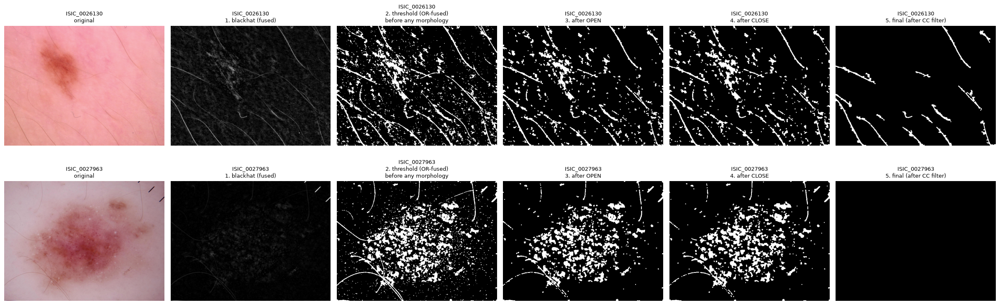

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Reuses HAIR_CONFIG from the previous validation driver.
# Pick a couple of the worst offenders from the last grid — visibly hairy,
# but poorly detected.
DIAGNOSTIC_IMAGE_IDS = ["ISIC_0027963", "ISIC_0026130"]

diagnostic_paths = [p for p in image_paths if p.stem in DIAGNOSTIC_IMAGE_IDS]

fig, axes = plt.subplots(len(diagnostic_paths), 6, figsize=(24, 4 * len(diagnostic_paths)))
if len(diagnostic_paths) == 1:
    axes = axes.reshape(1, -1)

for row, img_path in enumerate(diagnostic_paths):
    image_bgr = cv2.imread(str(img_path))
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

    # --- Stage 1: multi-scale BlackHat, fused ---
    blackhat_responses = []
    for k in HAIR_CONFIG["blackhat_kernel_sizes"]:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
        blackhat_responses.append(cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel))
    fused_blackhat = blackhat_responses[0]
    for r in blackhat_responses[1:]:
        fused_blackhat = np.maximum(fused_blackhat, r)

    # --- Stage 2: blur ---
    blurred = cv2.GaussianBlur(fused_blackhat, HAIR_CONFIG["gaussian_blur_ksize"], 0)

    # --- Stage 3: dual threshold, OR-fused ---
    adaptive_thresh = cv2.adaptiveThreshold(
        blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
        HAIR_CONFIG["adaptive_block_size"], HAIR_CONFIG["adaptive_C"],
    )
    _, otsu_thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    fused_thresh = cv2.bitwise_or(adaptive_thresh, otsu_thresh)

    # --- Stage 4: morphological open ---
    morph_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (HAIR_CONFIG["morph_kernel_size"],) * 2
    )
    opened = cv2.morphologyEx(fused_thresh, cv2.MORPH_OPEN, morph_kernel)

    # --- Stage 5: morphological close ---
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, morph_kernel)

    # --- Stage 6: final CC-filtered mask (using the real function) ---
    final_mask = detect_hair_mask(image_bgr, **HAIR_CONFIG)

    stage_images = [
        (cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB), "original"),
        (fused_blackhat, "1. blackhat (fused)"),
        (fused_thresh, "2. threshold (OR-fused)\nbefore any morphology"),
        (opened, "3. after OPEN"),
        (closed, "4. after CLOSE"),
        (final_mask, "5. final (after CC filter)"),
    ]

    for col, (img, title) in enumerate(stage_images):
        cmap = "gray" if img.ndim == 2 else None
        axes[row, col].imshow(img, cmap=cmap)
        axes[row, col].set_title(f"{img_path.stem}\n{title}", fontsize=9)
        axes[row, col].axis("off")

    # Quantify pixel loss at each stage
    print(f"\n{img_path.stem}:")
    print(f"  threshold (pre-morphology) : {(fused_thresh > 0).sum()} px")
    print(f"  after OPEN                 : {(opened > 0).sum()} px")
    print(f"  after CLOSE                : {(closed > 0).sum()} px")
    print(f"  final (after CC filter)    : {(final_mask > 0).sum()} px")

plt.tight_layout()
plt.show()

HAIR OVERLAY CHECK

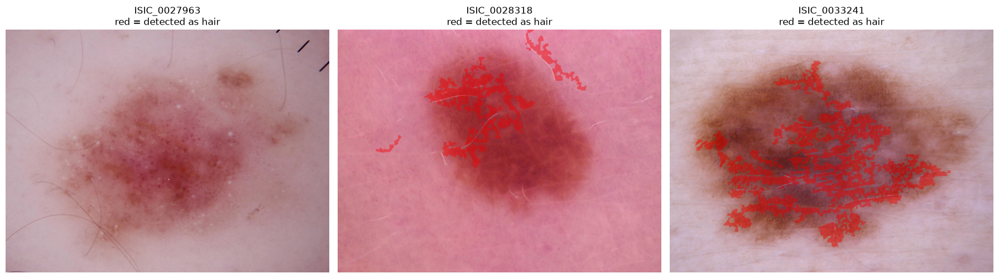

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# The two "clustered/web" cases from the last grid, worth checking directly
OVERLAY_IMAGE_IDS = ["ISIC_0028318", "ISIC_0033241", "ISIC_0027963"]

overlay_paths = [p for p in image_paths if p.stem in OVERLAY_IMAGE_IDS]

fig, axes = plt.subplots(1, len(overlay_paths), figsize=(6 * len(overlay_paths), 6))
if len(overlay_paths) == 1:
    axes = [axes]

for ax, img_path in zip(axes, overlay_paths):
    image_bgr = cv2.imread(str(img_path))
    mask = detect_hair_mask(image_bgr, **HAIR_CONFIG)

    overlay = image_bgr.copy()
    overlay[mask > 0] = [0, 0, 255]  # BGR red

    blended = cv2.addWeighted(image_bgr, 0.6, overlay, 0.4, 0)

    ax.imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{img_path.stem}\nred = detected as hair")
    ax.axis("off")

plt.tight_layout()
plt.show()

HAIR MASK CONSTRAINED CHECK

ISIC_0027963: hair pixels = 0.00% (lesion interior excluded)
ISIC_0028318: hair pixels = 0.82% (lesion interior excluded)
ISIC_0033241: hair pixels = 0.00% (lesion interior excluded)


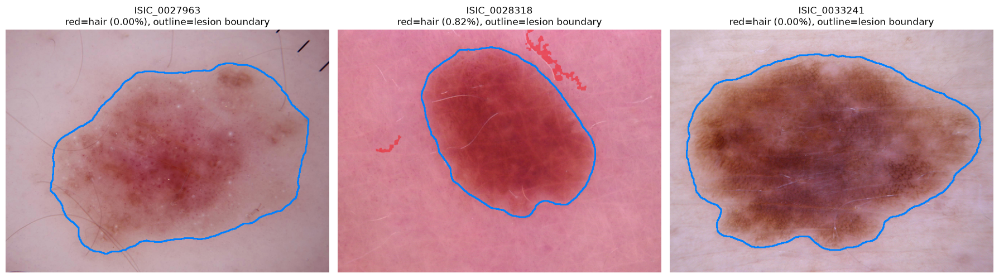

In [26]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Same problem images as before
CHECK_IMAGE_IDS = ["ISIC_0027963", "ISIC_0028318", "ISIC_0033241"]

check_paths = [p for p in image_paths if p.stem in CHECK_IMAGE_IDS]

# Build image_id -> lesion mask path lookup, reusing mask_paths from the
# mask-coverage step (Tschandl masks, already verified at 10015/10015 overlap)
lesion_mask_path_by_id = {mask_path_to_image_id(p): p for p in mask_paths}

fig, axes = plt.subplots(1, len(check_paths), figsize=(6 * len(check_paths), 6))
if len(check_paths) == 1:
    axes = [axes]

for ax, img_path in zip(axes, check_paths):
    image_id = img_path.stem
    image_bgr = cv2.imread(str(img_path))

    lesion_mask_path = lesion_mask_path_by_id.get(image_id)
    if lesion_mask_path is None:
        print(f"WARNING: no lesion mask found for {image_id}, skipping")
        continue

    lesion_mask = cv2.imread(str(lesion_mask_path), cv2.IMREAD_GRAYSCALE)
    if lesion_mask.shape != image_bgr.shape[:2]:
        lesion_mask = cv2.resize(
            lesion_mask, (image_bgr.shape[1], image_bgr.shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )
    # Binarise defensively in case of any anti-aliasing in the source PNG
    _, lesion_mask = cv2.threshold(lesion_mask, 127, 255, cv2.THRESH_BINARY)

    hair_mask = detect_hair_mask(image_bgr, lesion_mask=lesion_mask, **HAIR_CONFIG)
    hair_pixel_pct = 100 * (hair_mask > 0).sum() / hair_mask.size

    # Overlay: red = detected hair, blue outline = lesion boundary (for reference only)
    overlay = image_bgr.copy()
    overlay[hair_mask > 0] = [0, 0, 255]
    blended = cv2.addWeighted(image_bgr, 0.6, overlay, 0.4, 0)

    lesion_contours, _ = cv2.findContours(lesion_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(blended, lesion_contours, -1, (255, 128, 0), 2)  # blue-ish boundary

    ax.imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{image_id}\nred=hair ({hair_pixel_pct:.2f}%), outline=lesion boundary")
    ax.axis("off")

    print(f"{image_id}: hair pixels = {hair_pixel_pct:.2f}% (lesion interior excluded)")

plt.tight_layout()
plt.show()

FULL DATASET HAIR PASS

In [27]:
import cv2
import numpy as np
import pandas as pd
from tqdm import tqdm

# --- Output location for the full mask set ---
HAIR_MASK_DIR = ARTIFACTS_DIR / "HairMasks"
HAIR_MASK_DIR.mkdir(parents=True, exist_ok=True)

# --- Lesion mask lookup (Tschandl masks, already verified at 10015/10015 overlap) ---
lesion_mask_path_by_id = {mask_path_to_image_id(p): p for p in mask_paths}

records = []
failed = []

for img_path in tqdm(image_paths, desc="Hair detection (full dataset)"):
    image_id = img_path.stem

    lesion_mask_path = lesion_mask_path_by_id.get(image_id)
    if lesion_mask_path is None:
        failed.append((image_id, "no lesion mask found"))
        continue

    try:
        image_bgr = cv2.imread(str(img_path))
        if image_bgr is None:
            failed.append((image_id, "failed to load image"))
            continue

        lesion_mask = cv2.imread(str(lesion_mask_path), cv2.IMREAD_GRAYSCALE)
        if lesion_mask is None:
            failed.append((image_id, "failed to load lesion mask"))
            continue

        if lesion_mask.shape != image_bgr.shape[:2]:
            lesion_mask = cv2.resize(
                lesion_mask, (image_bgr.shape[1], image_bgr.shape[0]),
                interpolation=cv2.INTER_NEAREST,
            )
        _, lesion_mask = cv2.threshold(lesion_mask, 127, 255, cv2.THRESH_BINARY)

        hair_mask = detect_hair_mask(image_bgr, lesion_mask=lesion_mask, **HAIR_CONFIG)
        hair_pixel_count = int((hair_mask > 0).sum())
        hair_pixel_pct = 100 * hair_pixel_count / hair_mask.size

        # Persist mask to disk (checklist requirement — reusable without recomputation)
        mask_out_path = HAIR_MASK_DIR / f"{image_id}_hairmask.png"
        cv2.imwrite(str(mask_out_path), hair_mask)

        records.append({
            "image_id": image_id,
            "hair_pixel_count": hair_pixel_count,
            "hair_pixel_pct": hair_pixel_pct,
        })

    except Exception as e:
        failed.append((image_id, str(e)))

print(f"\nProcessed: {len(records)} / {len(image_paths)}")
print(f"Failed: {len(failed)}")
if failed:
    for image_id, reason in failed[:20]:
        print(f"  {image_id}: {reason}")
    if len(failed) > 20:
        print(f"  ... and {len(failed) - 20} more")

# --- Save stats ---
hair_stats_df = pd.DataFrame(records)
hair_stats_df = hair_stats_df.merge(
    metadata_df[["image_id", "dx"]], on="image_id", how="left"
)

stats_out_path = ARTIFACTS_DIR / "hair_coverage_stats.csv"
hair_stats_df.to_csv(stats_out_path, index=False)
print(f"\nSaved per-image hair coverage stats to: {stats_out_path}")

Hair detection (full dataset): 100%|██████████| 10015/10015 [01:40<00:00, 99.98it/s] 


Processed: 10015 / 10015
Failed: 0

Saved per-image hair coverage stats to: T:\Thesis - Development\Resources\Artifacts\hair_coverage_stats.csv


HAIR COVERAGE ANALYSIS

Hair pixel % — summary statistics across all images:
count    10015.000000
mean         1.340688
std          2.318146
min          0.000000
25%          0.000000
50%          0.412593
75%          1.640741
max         27.218148
Name: hair_pixel_pct, dtype: float64

Images with hair_pixel_pct < 0.1%: 3421 (34.2%)
Images with exactly 0.00% detected: 2874 (28.7%)

Low-detection rate by class:
        sum  count        pct
dx                           
mel     490   1113  44.025157
bkl     418   1099  38.034577
nv     2239   6705  33.392990
vasc     39    142  27.464789
akiec    85    327  25.993884
bcc     123    514  23.929961
df       27    115  23.478261


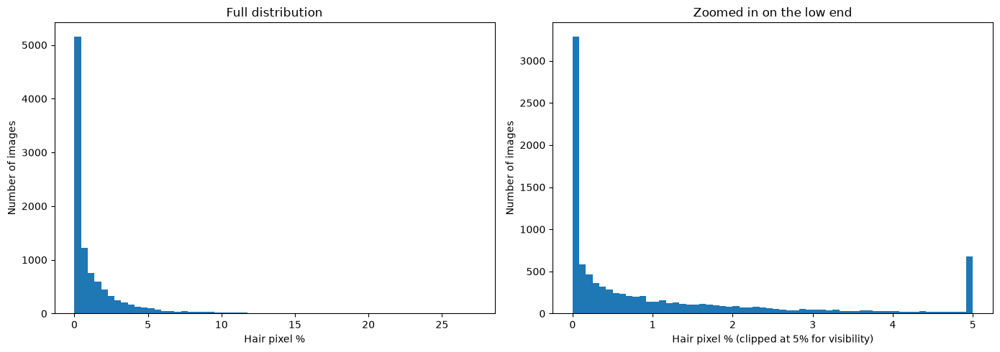


Saved list of low-detection images to: T:\Thesis - Development\Resources\Artifacts\low_hair_detection_images.csv


In [28]:
import matplotlib.pyplot as plt

# --- Summary statistics ---
print("Hair pixel % — summary statistics across all images:")
print(hair_stats_df["hair_pixel_pct"].describe())

# --- How common is the "near-zero detection" pattern (like ISIC_0027963)? ---
LOW_DETECTION_THRESHOLD = 0.1  # % — adjust if needed after seeing the distribution

n_low = (hair_stats_df["hair_pixel_pct"] < LOW_DETECTION_THRESHOLD).sum()
pct_low = 100 * n_low / len(hair_stats_df)
print(f"\nImages with hair_pixel_pct < {LOW_DETECTION_THRESHOLD}%: {n_low} ({pct_low:.1f}%)")

n_zero = (hair_stats_df["hair_pixel_pct"] == 0.0).sum()
pct_zero = 100 * n_zero / len(hair_stats_df)
print(f"Images with exactly 0.00% detected: {n_zero} ({pct_zero:.1f}%)")

# --- Does low detection cluster in any particular class? ---
print("\nLow-detection rate by class:")
low_by_class = (
    hair_stats_df.assign(is_low=hair_stats_df["hair_pixel_pct"] < LOW_DETECTION_THRESHOLD)
    .groupby("dx")["is_low"]
    .agg(["sum", "count"])
    .assign(pct=lambda d: 100 * d["sum"] / d["count"])
    .sort_values("pct", ascending=False)
)
print(low_by_class.to_string())

# --- Histogram ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(hair_stats_df["hair_pixel_pct"], bins=60)
axes[0].set_xlabel("Hair pixel %")
axes[0].set_ylabel("Number of images")
axes[0].set_title("Full distribution")

axes[1].hist(hair_stats_df["hair_pixel_pct"].clip(upper=5), bins=60)
axes[1].set_xlabel("Hair pixel % (clipped at 5% for visibility)")
axes[1].set_ylabel("Number of images")
axes[1].set_title("Zoomed in on the low end")

plt.tight_layout()
plt.show()

# --- Save the low-detection image list for reference ---
low_detection_ids = hair_stats_df[hair_stats_df["hair_pixel_pct"] < LOW_DETECTION_THRESHOLD]
low_detection_out_path = ARTIFACTS_DIR / "low_hair_detection_images.csv"
low_detection_ids.to_csv(low_detection_out_path, index=False)
print(f"\nSaved list of low-detection images to: {low_detection_out_path}")

Zero Detection Check

Total zero-detection images: 2874


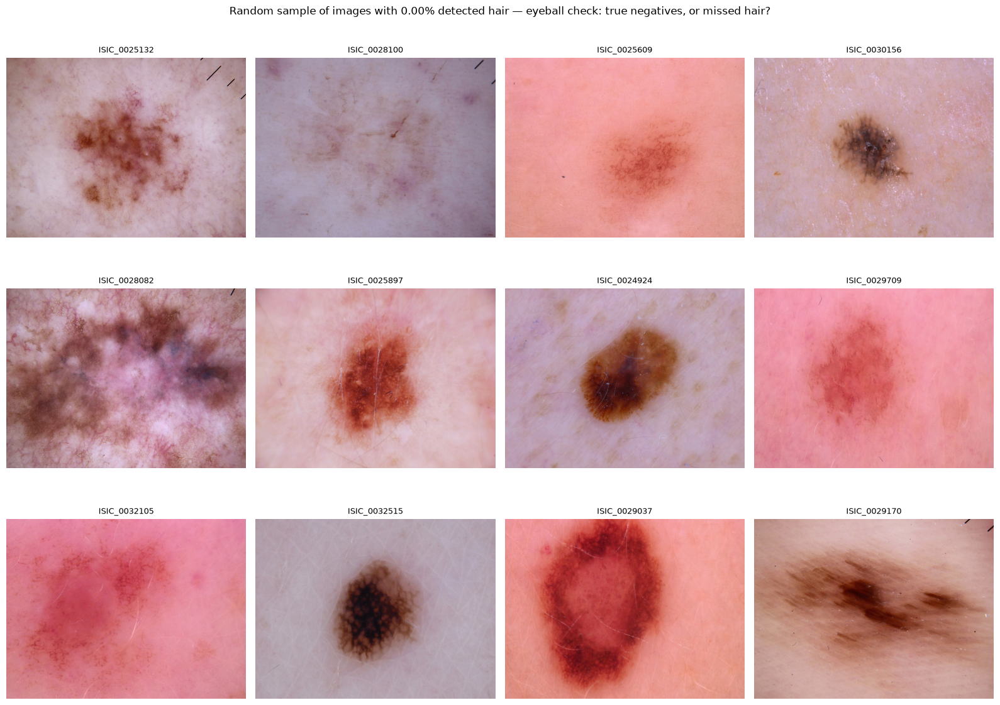


For each image above, note whether it's genuinely hair-free or has visible hair that was missed.

Correlation between lesion area % and hair pixel %:
                 lesion_area_pct  hair_pixel_pct
lesion_area_pct         1.000000       -0.215362
hair_pixel_pct         -0.215362        1.000000

Mean lesion area % — zero-detection group vs. non-zero group:
hair_pixel_pct
False    24.276818
True     32.485559
Name: lesion_area_pct, dtype: float64

Mean lesion area % by class (for comparison against the earlier low-detection-by-class table):
dx
akiec    40.297574
mel      32.444278
bkl      31.961169
df       31.194963
bcc      26.007072
nv       24.339612
vasc     15.204144
Name: lesion_area_pct, dtype: float64


In [29]:
import cv2
import random
import matplotlib.pyplot as plt
import numpy as np

# --- Part A: visually sample the "0% detected" bucket ---
zero_detection_ids = hair_stats_df[hair_stats_df["hair_pixel_pct"] == 0.0]["image_id"].tolist()
print(f"Total zero-detection images: {len(zero_detection_ids)}")

rng = random.Random(123)  # temporary sampling seed for this check only
sample_ids = rng.sample(zero_detection_ids, 12)

image_path_by_id = {p.stem: p for p in image_paths}

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for ax, image_id in zip(axes, sample_ids):
    img_path = image_path_by_id[image_id]
    image_bgr = cv2.imread(str(img_path))
    ax.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    ax.set_title(image_id, fontsize=9)
    ax.axis("off")

plt.suptitle("Random sample of images with 0.00% detected hair — eyeball check: true negatives, or missed hair?")
plt.tight_layout()
plt.show()

print("\nFor each image above, note whether it's genuinely hair-free or has visible hair that was missed.")

# --- Part B: check the lesion-size confound directly ---
# Compute lesion area % for every image and correlate against hair_pixel_pct / zero-detection
lesion_area_records = []
for image_id, mask_path in lesion_mask_path_by_id.items():
    lesion_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    _, lesion_mask = cv2.threshold(lesion_mask, 127, 255, cv2.THRESH_BINARY)
    lesion_area_pct = 100 * (lesion_mask > 0).sum() / lesion_mask.size
    lesion_area_records.append({"image_id": image_id, "lesion_area_pct": lesion_area_pct})

lesion_area_df = pd.DataFrame(lesion_area_records)
merged = hair_stats_df.merge(lesion_area_df, on="image_id", how="left")

print("\nCorrelation between lesion area % and hair pixel %:")
print(merged[["lesion_area_pct", "hair_pixel_pct"]].corr())

print("\nMean lesion area % — zero-detection group vs. non-zero group:")
print(merged.groupby(merged["hair_pixel_pct"] == 0.0)["lesion_area_pct"].mean())

print("\nMean lesion area % by class (for comparison against the earlier low-detection-by-class table):")
print(merged.groupby("dx")["lesion_area_pct"].mean().sort_values(ascending=False))

CLAHE


In [31]:
import cv2
import numpy as np


def apply_clahe(
    image_bgr: np.ndarray,
    clip_limit: float = 2.0,
    tile_grid_size: tuple = (8, 8),
) -> np.ndarray:
    """
    Apply CLAHE (Contrast Limited Adaptive Histogram Equalization) to the
    L (lightness) channel only, in LAB color space.

    Never applied per-RGB-channel — that would shift hue, and dermoscopic
    lesion color is diagnostically meaningful (part of the ABCDE criteria).
    Restricting to the L channel boosts local contrast without touching color.

    Args:
        image_bgr: input BGR image
        clip_limit: threshold for contrast limiting — higher values allow
            more contrast (and more noise amplification)
        tile_grid_size: size of the grid for histogram equalization,
            (rows, cols) — smaller tiles = more local adaptivity

    Returns:
        BGR image with CLAHE applied to lightness only.
    """
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l_channel_enhanced = clahe.apply(l_channel)

    lab_enhanced = cv2.merge([l_channel_enhanced, a_channel, b_channel])
    image_bgr_enhanced = cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2BGR)

    return image_bgr_enhanced

CLAHE VALIDATION DRIVER

ISIC_0029611: L-channel std dev 27.74 -> 32.88 (+18.5%)
ISIC_0026777: L-channel std dev 21.49 -> 24.94 (+16.1%)
ISIC_0030774: L-channel std dev 28.29 -> 31.98 (+13.0%)
ISIC_0025097: L-channel std dev 38.87 -> 44.61 (+14.7%)
ISIC_0025492: L-channel std dev 15.75 -> 22.79 (+44.7%)
ISIC_0033085: L-channel std dev 28.28 -> 29.30 (+3.6%)
ISIC_0025848: L-channel std dev 30.55 -> 35.07 (+14.8%)
ISIC_0030297: L-channel std dev 25.85 -> 36.43 (+40.9%)


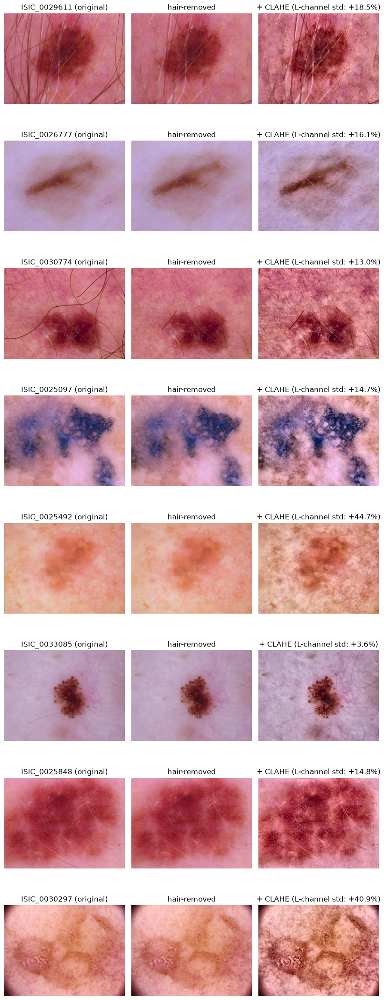


Check the grid above for:
  1. Visible contrast/detail improvement without color/hue shift
  2. No obvious noise amplification (sensor speckle, JPEG blocking becoming visible)
  3. Lesion border and internal structure still look natural, not artificial/oversharpened


In [32]:
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

CLAHE_CONFIG = {
    "clip_limit": 2.0,
    "tile_grid_size": (8, 8),
}

N_SAMPLES = 8
SAMPLE_SEED = 7  # temporary sampling seed for this validation only

rng = random.Random(SAMPLE_SEED)
sample_paths = rng.sample(image_paths, N_SAMPLES)

image_path_by_id = {p.stem: p for p in image_paths}
HAIR_MASK_DIR = ARTIFACTS_DIR / "HairMasks"

fig, axes = plt.subplots(N_SAMPLES, 3, figsize=(9, 3 * N_SAMPLES))

for i, img_path in enumerate(sample_paths):
    image_id = img_path.stem
    image_bgr = cv2.imread(str(img_path))

    # Reuse the already-persisted hair mask (no recomputation)
    mask_path = HAIR_MASK_DIR / f"{image_id}_hairmask.png"
    hair_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    hair_removed = remove_hair(image_bgr, hair_mask, **DILATE_CONFIG)
    clahe_applied = apply_clahe(hair_removed, **CLAHE_CONFIG)

    # Contrast metric: std dev of the L channel, before vs after
    l_before = cv2.cvtColor(hair_removed, cv2.COLOR_BGR2LAB)[:, :, 0]
    l_after = cv2.cvtColor(clahe_applied, cv2.COLOR_BGR2LAB)[:, :, 0]
    contrast_gain_pct = 100 * (l_after.std() - l_before.std()) / l_before.std()

    axes[i, 0].imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{image_id} (original)")
    axes[i, 1].imshow(cv2.cvtColor(hair_removed, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title("hair-removed")
    axes[i, 2].imshow(cv2.cvtColor(clahe_applied, cv2.COLOR_BGR2RGB))
    axes[i, 2].set_title(f"+ CLAHE (L-channel std: {contrast_gain_pct:+.1f}%)")

    for ax in axes[i]:
        ax.axis("off")

    print(f"{image_id}: L-channel std dev {l_before.std():.2f} -> {l_after.std():.2f} ({contrast_gain_pct:+.1f}%)")

plt.tight_layout()
plt.show()

print("\nCheck the grid above for:")
print("  1. Visible contrast/detail improvement without color/hue shift")
print("  2. No obvious noise amplification (sensor speckle, JPEG blocking becoming visible)")
print("  3. Lesion border and internal structure still look natural, not artificial/oversharpened")

MISS HAIR DIAGNOSTICS

In [33]:
import cv2
from pathlib import Path

SUSPECT_IDS = ["ISIC_0029611", "ISIC_0030774", "ISIC_0033085"]

HAIR_MASK_DIR = ARTIFACTS_DIR / "HairMasks"

for image_id in SUSPECT_IDS:
    print(f"\n--- {image_id} ---")

    # 1. What did the full-dataset pass record for this image?
    row = hair_stats_df[hair_stats_df["image_id"] == image_id]
    if row.empty:
        print("  NOT FOUND in hair_stats_df — full-dataset pass never processed this image")
        continue
    recorded_pct = row["hair_pixel_pct"].values[0]
    print(f"  Recorded hair_pixel_pct in CSV: {recorded_pct:.4f}%")

    # 2. Does the mask file actually exist, and what does it contain right now?
    mask_path = HAIR_MASK_DIR / f"{image_id}_hairmask.png"
    print(f"  Mask file exists: {mask_path.exists()}  ({mask_path})")

    if mask_path.exists():
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if mask is None:
            print("  Mask file exists but failed to load (corrupt?)")
        else:
            actual_pct = 100 * (mask > 0).sum() / mask.size
            print(f"  Actual mask white-pixel %: {actual_pct:.4f}%  (shape: {mask.shape})")

    # 3. Re-run detection fresh, right now, and compare
    img_path = image_path_by_id[image_id]
    image_bgr = cv2.imread(str(img_path))
    lesion_mask_path = lesion_mask_path_by_id.get(image_id)
    lesion_mask = cv2.imread(str(lesion_mask_path), cv2.IMREAD_GRAYSCALE)
    if lesion_mask.shape != image_bgr.shape[:2]:
        lesion_mask = cv2.resize(lesion_mask, (image_bgr.shape[1], image_bgr.shape[0]), interpolation=cv2.INTER_NEAREST)
    _, lesion_mask = cv2.threshold(lesion_mask, 127, 255, cv2.THRESH_BINARY)

    fresh_mask = detect_hair_mask(image_bgr, lesion_mask=lesion_mask, **HAIR_CONFIG)
    fresh_pct = 100 * (fresh_mask > 0).sum() / fresh_mask.size
    print(f"  Freshly recomputed hair_pixel_pct: {fresh_pct:.4f}%")


--- ISIC_0029611 ---
  Recorded hair_pixel_pct in CSV: 8.8763%
  Mask file exists: True  (T:\Thesis - Development\Resources\Artifacts\HairMasks\ISIC_0029611_hairmask.png)
  Actual mask white-pixel %: 8.8763%  (shape: (450, 600))
  Freshly recomputed hair_pixel_pct: 8.8763%

--- ISIC_0030774 ---
  Recorded hair_pixel_pct in CSV: 4.7274%
  Mask file exists: True  (T:\Thesis - Development\Resources\Artifacts\HairMasks\ISIC_0030774_hairmask.png)
  Actual mask white-pixel %: 4.7274%  (shape: (450, 600))
  Freshly recomputed hair_pixel_pct: 4.7274%

--- ISIC_0033085 ---
  Recorded hair_pixel_pct in CSV: 0.0963%
  Mask file exists: True  (T:\Thesis - Development\Resources\Artifacts\HairMasks\ISIC_0033085_hairmask.png)
  Actual mask white-pixel %: 0.0963%  (shape: (450, 600))
  Freshly recomputed hair_pixel_pct: 0.0963%


REMOVAL QUALITY CHECK


ISIC_0029611: mean abs pixel diff INSIDE mask = 31.38, overall = 2.98 (0 = literally no change)
ISIC_0030774: mean abs pixel diff INSIDE mask = 40.51, overall = 2.06 (0 = literally no change)
ISIC_0033085: mean abs pixel diff INSIDE mask = 10.99, overall = 0.01 (0 = literally no change)


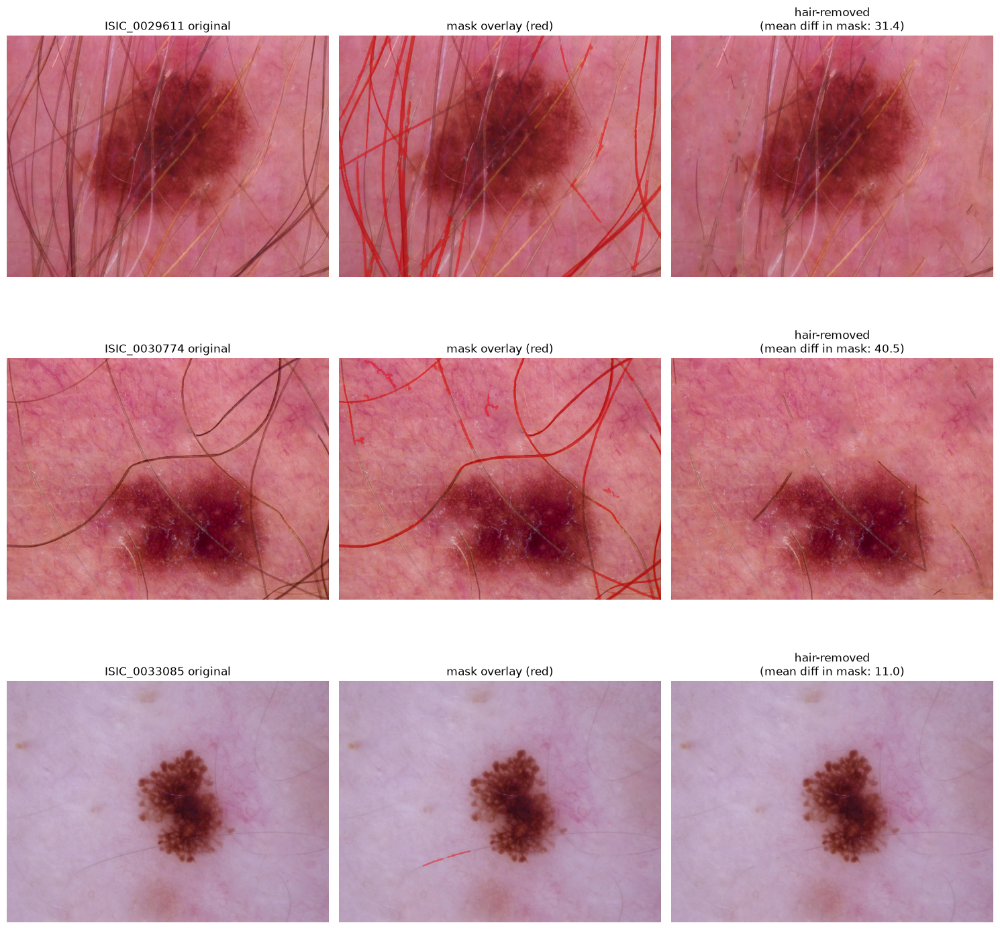

In [34]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

SUSPECT_IDS = ["ISIC_0029611", "ISIC_0030774", "ISIC_0033085"]
HAIR_MASK_DIR = ARTIFACTS_DIR / "HairMasks"

fig, axes = plt.subplots(len(SUSPECT_IDS), 3, figsize=(15, 5 * len(SUSPECT_IDS)))

for row, image_id in enumerate(SUSPECT_IDS):
    img_path = image_path_by_id[image_id]
    image_bgr = cv2.imread(str(img_path))

    mask_path = HAIR_MASK_DIR / f"{image_id}_hairmask.png"
    hair_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    hair_removed = remove_hair(image_bgr, hair_mask, **DILATE_CONFIG)

    # Quantify actual pixel change WITHIN the masked (hair) region only
    diff = cv2.absdiff(image_bgr, hair_removed)
    diff_gray = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)
    mean_diff_in_mask = diff_gray[hair_mask > 0].mean() if (hair_mask > 0).any() else 0.0
    mean_diff_overall = diff_gray.mean()

    print(f"{image_id}: mean abs pixel diff INSIDE mask = {mean_diff_in_mask:.2f}, "
          f"overall = {mean_diff_overall:.2f} (0 = literally no change)")

    # Overlay mask in red on original, for direct visual reference against the removed result
    overlay = image_bgr.copy()
    overlay[hair_mask > 0] = [0, 0, 255]
    blended = cv2.addWeighted(image_bgr, 0.6, overlay, 0.4, 0)

    axes[row, 0].imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f"{image_id} original")
    axes[row, 1].imshow(cv2.cvtColor(blended, cv2.COLOR_BGR2RGB))
    axes[row, 1].set_title("mask overlay (red)")
    axes[row, 2].imshow(cv2.cvtColor(hair_removed, cv2.COLOR_BGR2RGB))
    axes[row, 2].set_title(f"hair-removed\n(mean diff in mask: {mean_diff_in_mask:.1f})")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()